# Домашняя работа №2. Прогнозирование продаж

## 1. Подготовка данных


In [37]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from xgboost import XGBRegressor

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True

stock_code = '22423'


def prepare_sales(df):
    valid = (
        ~df['InvoiceNo'].fillna('').str.startswith('C')
        & df['InvoiceDate'].notna()
        & df['StockCode'].notna()
        & (df['Quantity'] > 0)
        & (df['UnitPrice'] > 0)
    )
    sales = df.loc[valid].copy()
    sales['date'] = pd.to_datetime(sales['InvoiceDate']).dt.normalize()
    return sales


def get_series(sales):
    item = sales.loc[sales['StockCode'] == stock_code]
    dates = pd.date_range(sales['date'].min(), sales['date'].max(), freq='D')
    shop_days = sales['date'].unique()

    daily = item.groupby('date')['Quantity'].sum().reindex(dates).astype(float)
    daily.loc[daily.isna() & daily.index.isin(shop_days)] = 0
    weekly = daily.resample('W-SUN').sum(min_count=1)
    monthly = daily.resample('MS').sum(min_count=1)
    return daily, weekly, monthly


data_file = next(Path('/kaggle/input').rglob('Online Retail.xlsx'))
raw = pd.read_excel(data_file, dtype={'InvoiceNo': str, 'StockCode': str})
sales = prepare_sales(raw)
daily, weekly, monthly = get_series(sales)

print('Исходных строк:', len(raw))
print('Дневных наблюдений:', daily.notna().sum(), 'из', len(daily))
print('Недель:', len(weekly), '| Месяцев:', len(monthly))

Исходных строк: 541909
Дневных наблюдений: 305 из 374
Недель: 54 | Месяцев: 13


Для недельного ряда беру самый длинный непрерывный участок полных календарных недель. Для месячного оставляю период с декабря 2010 по ноябрь 2011 года: данные начинаются 1 декабря 2010 года, а декабрь 2011 года неполный. Дневной ряд оставляю с ежедневным шагом.

In [38]:
def longest_part(s):
    groups = s.notna().ne(s.notna().shift()).cumsum()
    parts = [part for _, part in s.dropna().groupby(groups[s.notna()])]
    return max(parts, key=len)


week_full = weekly.loc[
    (weekly.index - pd.Timedelta(days=6) >= daily.index.min())
    & (weekly.index <= daily.index.max())
]
week_full = longest_part(week_full)

month_full = monthly.loc[
    (monthly.index >= daily.index.min())
    & (monthly.index + pd.offsets.MonthEnd(0) <= daily.index.max())
]

series = {'День': daily, 'Неделя': week_full, 'Месяц': month_full}
horizons = {'День': [1, 7, 31, 61], 'Неделя': [1, 4, 8], 'Месяц': [1, 2]}


def split_series(s, test_size):
    return s.iloc[:-test_size].copy(), s.iloc[-test_size:].copy()


def fill_train(s, name):
    s = s.copy()
    if name == 'День':
        for day in range(7):
            mask = (s.index.dayofweek == day) & s.isna()
            value = s.loc[(s.index.dayofweek == day) & s.notna()].median()
            s.loc[mask] = 0 if pd.isna(value) else value
    return s.ffill().bfill()


train = {}
test = {}
train_ready = {}
for name, s in series.items():
    train[name], test[name] = split_series(s, max(horizons[name]))
    train_ready[name] = fill_train(train[name], name)
    assert len(train_ready[name]) > max(horizons[name])
    assert train[name].index.max() < test[name].index.min()
    assert train_ready[name].notna().all()

print(pd.DataFrame({
    name: {'Обучение': len(train[name]), 'Тест': len(test[name]),
           'Первый тестовый период': str(test[name].index[0].date())}
    for name in series
}).T.to_string())

       Обучение Тест Первый тестовый период
День        313   61             2011-10-10
Неделя       40    8             2011-10-16
Месяц        10    2             2011-10-01


Для обучения дневные пропуски заполняю медианой продаж того же дня недели, рассчитанной только по обучающей части. Для суббот, по которым нет наблюдений, использую ноль.

Тестовые значения не заполняю: метрики считаю только по датам с известными продажами. Недельные и месячные суммы также могут быть неполными из-за отсутствующих записей магазина.

## 2. Модели

Сравниваю три подхода: Naive, SES и XGBoost. Все модели используют одну и ту же обучающую часть. 

In [39]:
lags = {'День': [1, 2, 7, 14], 'Неделя': [1, 2, 4, 8], 'Месяц': [1, 2, 3]}


def make_lags(s, lag_list):
    x = pd.DataFrame({f'lag_{k}': s.shift(k) for k in lag_list}, index=s.index)
    x['y'] = s
    return x.dropna()


def predict_naive(s, steps):
    return np.repeat(s.iloc[-1], steps)


def predict_ses(s, steps):
    fit = SimpleExpSmoothing(s.to_numpy(), initialization_method='estimated').fit(optimized=True)
    return np.maximum(np.asarray(fit.forecast(steps)), 0)


def predict_xgboost(s, steps, lag_list):
    data = make_lags(s, lag_list)
    x = data.drop(columns='y')
    y = data['y']
    model = XGBRegressor(n_estimators=100, max_depth=2, learning_rate=0.05,
                         objective='reg:squarederror', n_jobs=1, random_state=42)
    model.fit(x, y)

    history = list(s.to_numpy())
    forecast = []
    for _ in range(steps):
        row = pd.DataFrame([[history[-k] for k in lag_list]], columns=x.columns)
        value = max(float(model.predict(row)[0]), 0)
        forecast.append(value)
        history.append(value)
    return np.array(forecast)


def get_predictions(s, name, steps):
    return {
        'Naive': predict_naive(s, steps),
        'SES': predict_ses(s, steps),
        'XGBoost': predict_xgboost(s, steps, lags[name]),
    }

## 3. Метрики и горизонты

Для каждой частоты строю прогнозы на разные горизонты: 1, 7, 31 и 61 день; 1, 4 и 8 недель; 1 и 2 месяца. Ошибку оцениваю на всём прогнозном интервале.
Для оценки качества использую MAE, RMSE и WAPE. На тестовом периоде метрики рассчитываю только по датам с известными значениями. 

In [40]:
def calc_metrics(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    mask = np.isfinite(actual) & np.isfinite(forecast)
    y = actual[mask]
    p = forecast[mask]
    if len(y) == 0:
        return {'N': 0, 'MAE': np.nan, 'RMSE': np.nan, 'WAPE, %': np.nan}
    err = y - p
    wape = 100 * np.sum(np.abs(err)) / np.sum(np.abs(y)) if np.sum(np.abs(y)) else np.nan
    return {'N': len(y), 'MAE': np.mean(np.abs(err)),
            'RMSE': np.sqrt(np.mean(err ** 2)), 'WAPE, %': wape}


predictions = {}
rows = []
for name in series:
    steps = max(horizons[name])
    predictions[name] = get_predictions(train_ready[name], name, steps)
    actual = test[name].to_numpy()
    for model, forecast in predictions[name].items():
        for h in horizons[name]:
            result = calc_metrics(actual[:h], forecast[:h])
            rows.append({'Частота': name, 'Модель': model, 'Горизонт': h, **result})

results = pd.DataFrame(rows)
assert len(results) == 3 * sum(len(v) for v in horizons.values())
assert results['N'].gt(0).all()
display(results.round(2))
results.to_csv('hw2_metrics.csv', index=False)

,Частота,Модель,Горизонт,N,MAE,RMSE,"WAPE, %"
0,День,Naive,1,1,2.00,2.00,9.09
1,День,Naive,7,6,15.67,20.73,43.93
2,День,Naive,31,27,20.44,30.84,57.62
3,День,Naive,61,53,24.70,38.89,60.24
4,День,SES,1,1,13.87,13.87,63.06
5,День,SES,7,6,12.33,13.57,34.58
6,День,SES,31,27,20.41,26.68,57.53
7,День,SES,61,53,22.18,33.14,54.10
8,День,XGBoost,1,1,4.20,4.20,19.09
9,День,XGBoost,7,6,12.49,14.71,35.03


## 4. Сравнение результатов

Для каждой модели и горизонта рассчитываю MAE, RMSE и WAPE на одинаковых тестовых данных. Основной метрикой сравнения использую MAE, а WAPE  для оценки относительной ошибки. При сравнении дневных, недельных и месячных прогнозов учитываю разный масштаб продаж.

In [41]:
best = (results.sort_values('MAE')
        .groupby(['Частота', 'Горизонт'], as_index=False)
        .first()[['Частота', 'Горизонт', 'Модель', 'MAE', 'RMSE', 'WAPE, %']])
print('Лучшая модель по MAE для каждого горизонта:')
display(best.round(2))

print('WAPE (%) по моделям:')
display(results.pivot_table(index=['Частота', 'Горизонт'],
                            columns='Модель', values='WAPE, %').round(2))

Лучшая модель по MAE для каждого горизонта:


,Частота,Горизонт,Модель,MAE,RMSE,"WAPE, %"
0,День,1,Naive,2.00,2.00,9.09
1,День,7,SES,12.33,13.57,34.58
2,День,31,SES,20.41,26.68,57.53
3,День,61,SES,22.18,33.14,54.10
4,Месяц,1,SES,134.07,134.07,12.38
5,Месяц,2,SES,119.57,120.45,11.19
6,Неделя,1,XGBoost,19.16,19.16,8.95
7,Неделя,4,XGBoost,45.82,53.50,20.46
8,Неделя,8,XGBoost,37.29,47.46,16.60


WAPE (%) по моделям:


Модель            Naive    SES  XGBoost
Частота Горизонт                       
День    1          9.09  63.06    19.09
        7         43.93  34.58    35.03
        31        57.62  57.53    74.80
        61        60.24  54.10    75.83
Месяц   1         28.53  12.38    15.06
        2         27.56  11.19    16.83
Неделя  1         91.12  12.30     8.95
        4         82.59  22.10    20.46
        8         82.08  16.68    16.60

## 5. Графики

Показываю фактические продажи и прогнозы на максимальном горизонте каждой частоты. Отдельно сравниваю WAPE при увеличении горизонта.

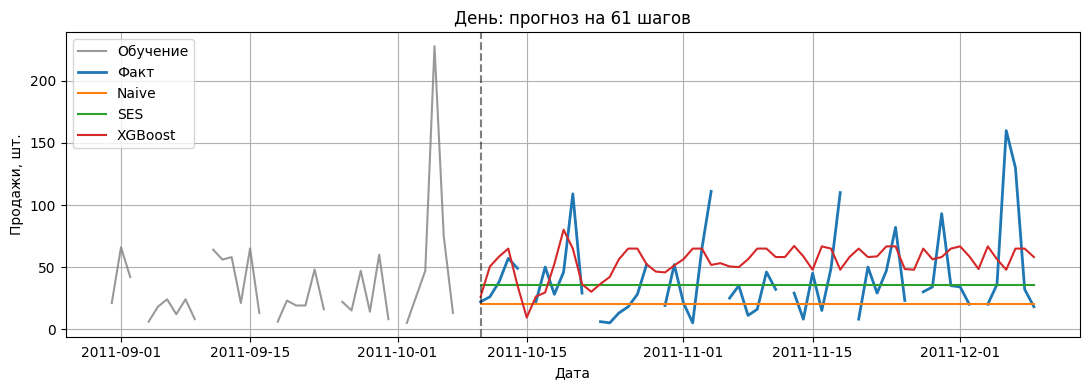

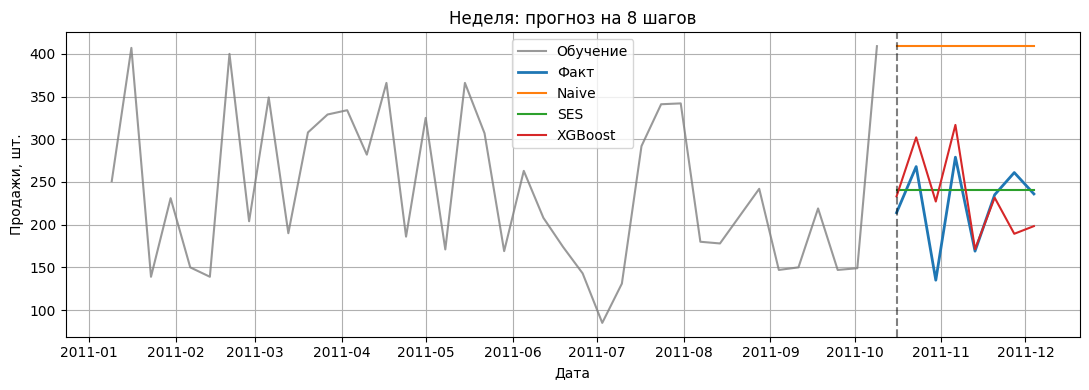

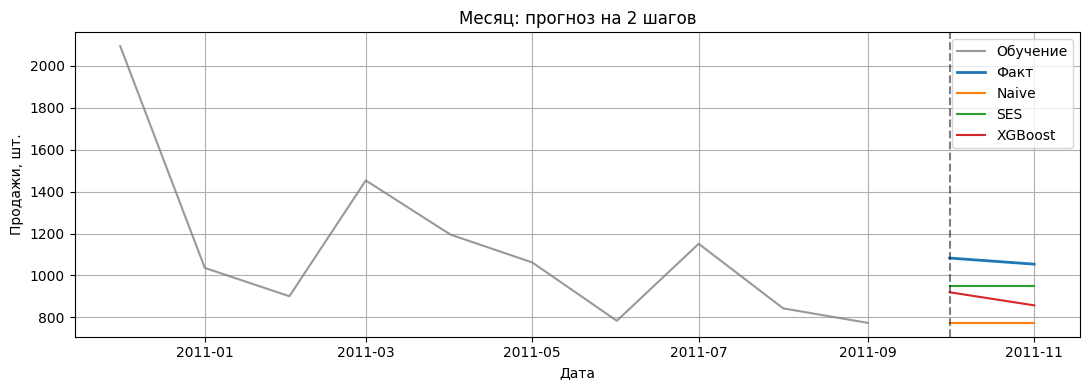

In [42]:
for name in series:
    fig, ax = plt.subplots(figsize=(11, 4))
    context = train[name].iloc[-min(40, len(train[name])):]
    ax.plot(context.index, context.to_numpy(), label='Обучение', color='grey', alpha=0.8)
    ax.plot(test[name].index, test[name].to_numpy(), label='Факт', linewidth=2)
    for model, forecast in predictions[name].items():
        ax.plot(test[name].index, forecast, label=model)
    ax.axvline(test[name].index[0], linestyle='--', color='black', alpha=0.5)
    ax.set(title=f'{name}: прогноз на {max(horizons[name])} шагов',
           xlabel='Дата', ylabel='Продажи, шт.')
    ax.legend()
    plt.tight_layout()
    plt.show()

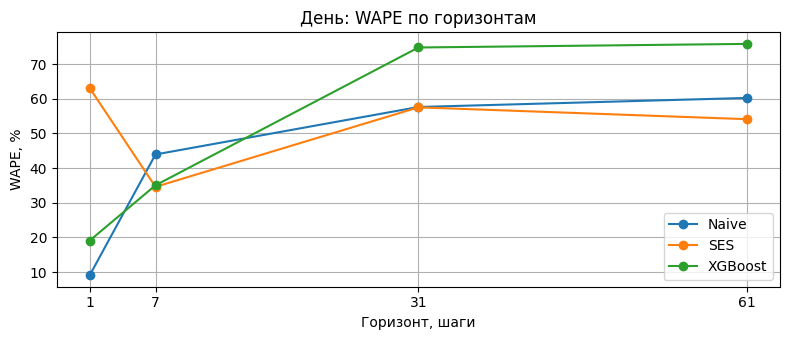

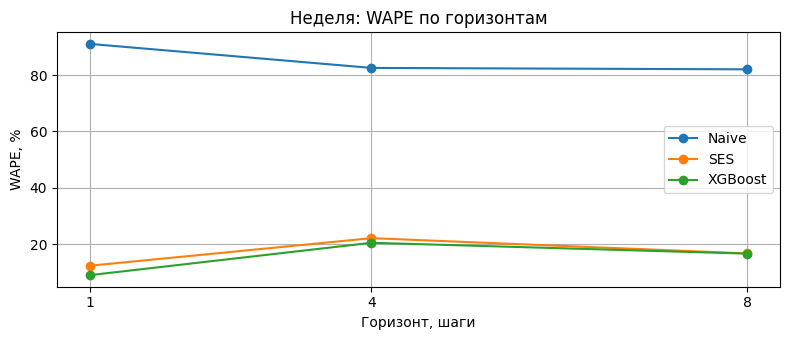

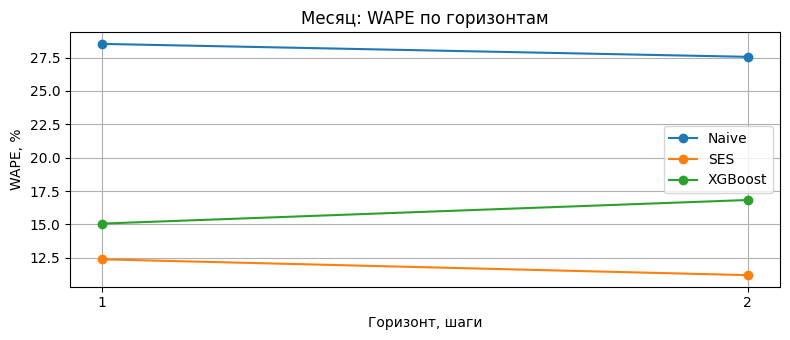

In [43]:
for name in series:
    subset = results[results['Частота'] == name]
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for model, group in subset.groupby('Модель'):
        ax.plot(group['Горизонт'], group['WAPE, %'], marker='o', label=model)
    ax.set(title=f'{name}: WAPE по горизонтам', xlabel='Горизонт, шаги', ylabel='WAPE, %')
    ax.set_xticks(horizons[name])
    ax.legend()
    plt.tight_layout()
    plt.show()

In [44]:
print('Лучшие модели по MAE:')
for name in series:
    part = best[best['Частота'] == name]
    for row in part.itertuples(index=False):
        print(f'{name}, h={row[1]}: {row[2]}, MAE={row[3]:.2f}, WAPE={row[5]:.1f}%')

Лучшие модели по MAE:
День, h=1: Naive, MAE=2.00, WAPE=9.1%
День, h=7: SES, MAE=12.33, WAPE=34.6%
День, h=31: SES, MAE=20.41, WAPE=57.5%
День, h=61: SES, MAE=22.18, WAPE=54.1%
Неделя, h=1: XGBoost, MAE=19.16, WAPE=9.0%
Неделя, h=4: XGBoost, MAE=45.82, WAPE=20.5%
Неделя, h=8: XGBoost, MAE=37.29, WAPE=16.6%
Месяц, h=1: SES, MAE=134.07, WAPE=12.4%
Месяц, h=2: SES, MAE=119.57, WAPE=11.2%


## 6. Walk-forward-проверка недельного ряда

Дополнительно проверяю устойчивость результатов на четырёх последовательных точках прогноза. Обучающая часть расширяется, а прогноз строится на 8 недель вперёд. Сравниваю ошибки на горизонтах 1, 4 и 8 недель.

Использую только первые 40 недель. Последние 8 недель основного теста в проверку не входят. Восьминедельные проверочные окна частично пересекаются.

Средняя ошибка по четырём точкам прогноза:


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


Модель,Naive,SES,XGBoost
Горизонт,,,
1,62.50,88.19,114.64
4,73.44,80.94,91.42
8,89.00,85.10,96.82


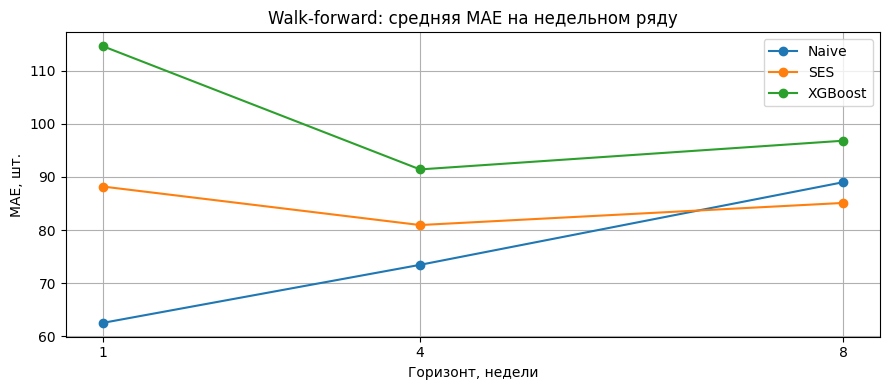

In [45]:
def walk_forward_week(s, starts):
    rows = []
    for fold, start in enumerate(starts, 1):
        history = fill_train(s.iloc[:start], 'Неделя')
        actual = s.iloc[start:start + 8].to_numpy()
        forecast = get_predictions(history, 'Неделя', 8)
        for model, values in forecast.items():
            for h in [1, 4, 8]:
                score = calc_metrics(actual[:h], values[:h])
                rows.append({'Фолд': fold, 'Модель': model, 'Горизонт': h, **score})
    return pd.DataFrame(rows)


wf = walk_forward_week(train['Неделя'], [20, 24, 28, 32])
wf_mean = wf.groupby(['Горизонт', 'Модель'], as_index=False)[['MAE', 'WAPE, %']].mean()

print('Средняя ошибка по четырём точкам прогноза:')
display(wf_mean.pivot(index='Горизонт', columns='Модель', values='MAE').round(2))

fig, ax = plt.subplots(figsize=(9, 4))
for model, part in wf_mean.groupby('Модель'):
    ax.plot(part['Горизонт'], part['MAE'], marker='o', label=model)
ax.set(title='Walk-forward: средняя MAE на недельном ряду',
       xlabel='Горизонт, недели', ylabel='MAE, шт.')
ax.set_xticks([1, 4, 8])
ax.legend()
plt.tight_layout()
plt.show()

На основном тесте XGBoost показал наименьшую MAE на всех недельных горизонтах. Но при walk-forward проверке результаты изменились: на горизонтах 1 и 4 недели меньшую среднюю ошибку показала Naive, а на 8 неделях  SES. Для XGBoost значения MAE составили 114,64; 91,42 и 96,82 соответственно.

По результатам преимущество XGBoost на основном тесте не подтвердилось при дополнительной проверке. При этом walk-forward проводился только на четырёх временных окнах, поэтому однозначно определить лучшую модель нельзя.

## 7. Выводы

На основном тесте для дневного ряда на горизонте 1 день наименьшую MAE показала Naive (2,00), а на 7, 31 и 61 день  SES (12,33; 20,41; 22,18). Для недельного ряда наименьшую ошибку на всех трёх горизонтах показала XGBoost (19,16; 45,82; 37,29), для месячного  SES (134,07 и 119,57).

Walk-forward-проверка недельного ряда дала другие результаты: в среднем Naive была лучше на горизонтах 1 и 4 недели, а SES  на 8 неделях. Поэтому по одному тестовому периоду нельзя уверенно назвать XGBoost лучшей моделью.

Для дневного прогноза на 61 день WAPE модели SES составляет 54,10%, поэтому точность такого прогноза остаётся невысокой. При увеличении горизонта ошибка может меняться неравномерно, поскольку оцениваются интервалы разной длины. Пропущенные дни и способ их заполнения при обучении тоже влияют на результат.

Для месячного ряда доступно только 10 месяцев обучения, а после формирования трёх лагов для XGBoost остаётся 7 примеров. Поэтому сравнение моделей на месячных данных менее надёжно. Простые методы оказались конкурентоспособными, а качество прогноза зависит от частоты, горизонта и тестового периода.